# Credit Risk: CDS Curves and the Merton Model

**Goal.** Measure the default risk of a company in the two ways used in practice:

- **The market view (CDS):** a credit default swap pays $(1-R)$ if the company defaults, in
  exchange for a running spread. From the CDS curve we back out the market-implied default
  probabilities (the *hazard rates*), then price and risk-manage a CDS position.
- **The balance-sheet view (Merton):** equity is a call option on the firm's assets,
  struck at the debt. From the share price and its volatility we infer the probability
  that assets end below the debt.

The CDS quotes are illustrative of a BBB-rated European corporate.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("credit.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/11-credit-risk-cds-merton")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from credit import HazardCurve, bootstrap, par_spread, upfront, cs01, _legs, merton_solve, merton_spread_curve

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"
r, R = 0.03, 0.40
mats = np.array([1, 2, 3, 5, 7, 10])
spreads = np.array([60, 75, 90, 120, 135, 150]) * 1e-4
pd.Series(spreads * 1e4, index=[f"{m}Y" for m in mats]).to_frame("CDS spread (bp)").T

,1Y,2Y,3Y,5Y,7Y,10Y
CDS spread (bp),60.0,75.0,90.0,120.0,135.0,150.0


## 1. From CDS spreads to default probabilities

With a hazard rate $\lambda(t)$, the probability of surviving to $t$ is
$S(t) = e^{-\int_0^t \lambda(u)du}$. A CDS has zero value at its par spread $s$:

$$s \times \underbrace{\sum_i \Delta_i\,D(t_i)\,S(t_i)}_{\text{risky PV01 (+ accrued on default)}}
= (1-R)\int_0^T D(t)\,dQ(\tau \le t)$$

The hazard rates are solved one segment at a time so that each quote is matched exactly.
A useful rule of thumb, the **credit triangle**: $s \approx \lambda (1 - R)$.

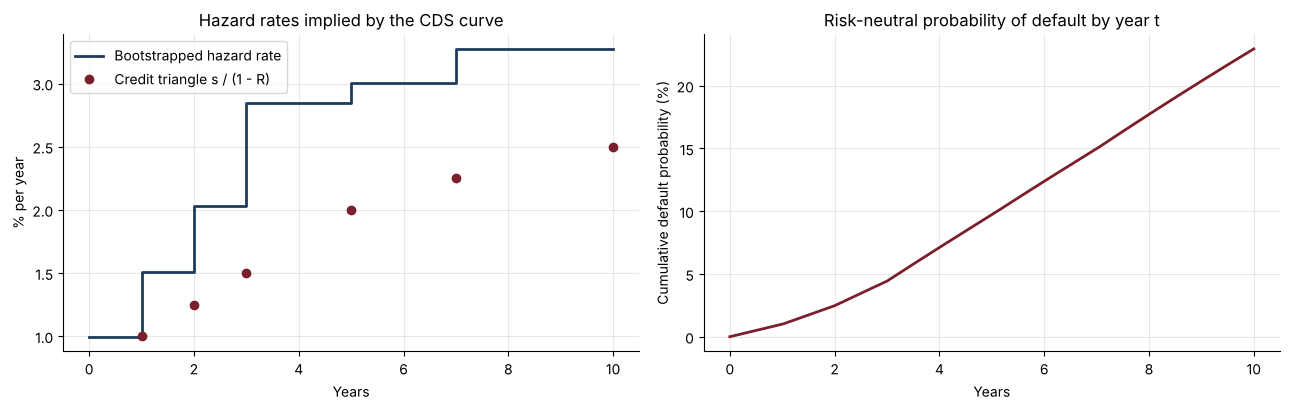

,Quote (bp),Repriced (bp),Hazard (%),Default prob. by T (%)
1Y,60.0,60.0,0.996,0.991
2Y,75.0,75.0,1.505,2.470
3Y,90.0,90.0,2.028,4.429
5Y,120.0,120.0,2.843,9.712
7Y,135.0,135.0,3.001,14.971
10Y,150.0,150.0,3.274,22.926


In [2]:
curve = bootstrap(mats, spreads, r, R)
t = np.linspace(0, 10, 501)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].step(np.concatenate([[0], mats]), np.concatenate([[curve.hazards[0]], curve.hazards]) * 100, where="pre",
             color=NAVY, lw=2, label="Bootstrapped hazard rate")
axes[0].plot(mats, spreads / (1 - R) * 100, "o", color=BORDEAUX, label="Credit triangle s / (1 - R)")
axes[0].set(xlabel="Years", ylabel="% per year", title="Hazard rates implied by the CDS curve"); axes[0].legend()
axes[1].plot(t, (1 - curve.survival(t)) * 100, color=BORDEAUX, lw=2)
axes[1].set(xlabel="Years", ylabel="Cumulative default probability (%)", title="Risk-neutral probability of default by year t")
plt.tight_layout(); plt.savefig("images/hazard_curve.png", dpi=150); plt.show()
check = pd.DataFrame({"Quote (bp)": spreads * 1e4, "Repriced (bp)": [par_spread(curve, T, r, R) * 1e4 for T in mats],
                      "Hazard (%)": curve.hazards * 100, "Default prob. by T (%)": (1 - curve.survival(mats)) * 100},
                     index=[f"{m}Y" for m in mats])
check.round(3)

These are **risk-neutral** probabilities: they include the premium investors demand for
bearing default risk, so they are higher than historical default rates for BBB issuers
(roughly 2% over 5 years against about 10% here).

## 2. Trading a CDS: upfront, risky PV01 and CS01

Since the 2009 "Big Bang", CDS trade with a **standard coupon** (100 bp for investment
grade) plus an upfront payment that settles the difference with the par spread.

In [3]:
rpv01, prot = _legs(curve, 5, r, R)
up = upfront(curve, 5, coupon=0.01, r=r, recovery=R)
sens = cs01(mats, spreads, 5, coupon=0.01, r=r, recovery=R)
notional = 10_000_000
pd.Series({"5Y par spread (bp)": par_spread(curve, 5, r, R) * 1e4, "Risky PV01 (years)": rpv01,
           "Protection leg (% notional)": prot * 100, "Upfront paid by buyer (% notional)": up * 100,
           "Upfront on 10m (EUR)": up * notional, "CS01 on 10m (EUR per bp)": sens * notional}).round(3).to_frame("5Y CDS, 100 bp coupon")

,"5Y CDS, 100 bp coupon"
5Y par spread (bp),120.000
Risky PV01 (years),4.448
Protection leg (% notional),5.337
Upfront paid by buyer (% notional),0.890
Upfront on 10m (EUR),88951.408
CS01 on 10m (EUR per bp),4410.236


**Scenario analysis for a protection buyer** on €10m: spread widening, a credit crisis,
and a jump to default (the buyer receives $1 - R$ minus the value already priced in).

In [4]:
rows = []
for label, bump in [("+25 bp", 25), ("+100 bp", 100), ("Crisis: x3 spreads", None)]:
    new_sp = spreads * 3 if bump is None else spreads + bump * 1e-4
    new_val = upfront(bootstrap(mats, new_sp, r, R), 5, 0.01, r, R)
    rows.append({"Scenario": label, "P&L (EUR)": (new_val - up) * notional})
rows.append({"Scenario": "Jump to default", "P&L (EUR)": ((1 - R) - up) * notional})
pd.DataFrame(rows).set_index("Scenario").round(0)

,P&L (EUR)
Scenario,
+25 bp,109202.0
+100 bp,423985.0
Crisis: x3 spreads,981359.0
Jump to default,5911049.0


## 3. The Merton model: credit risk from the share price

Shareholders own the firm's assets $V$ but must repay debt $D$ at $T$, so equity is a call:
$E = V N(d_1) - D e^{-rT} N(d_2)$, and by Itô, $\sigma_E E = N(d_1)\,\sigma_V V$. Two equations,
two unknowns ($V$, $\sigma_V$). Then:

- **Distance to default** $d_2$: how many standard deviations the assets are above the debt
- **Risk-neutral PD** $= N(-d_2)$, and the **credit spread** implied by the value of the debt

Example: equity market cap €40bn, equity volatility 45%, debt €80bn due in 1 year.

In [5]:
firm = merton_solve(E=40.0, sigma_E=0.45, D=80.0, T=1.0, r=r)
pd.Series(firm).round(4).to_frame("Merton output").T

,asset_value,asset_vol,distance_to_default,pd_risk_neutral,debt_value,credit_spread,leverage
Merton output,117.6205,0.1534,2.6307,0.0043,77.6205,0.0002,0.6802


**The equity-credit link.** As the share price falls, leverage rises and the distance to
default shrinks: equity investors and credit investors are looking at the same risk.

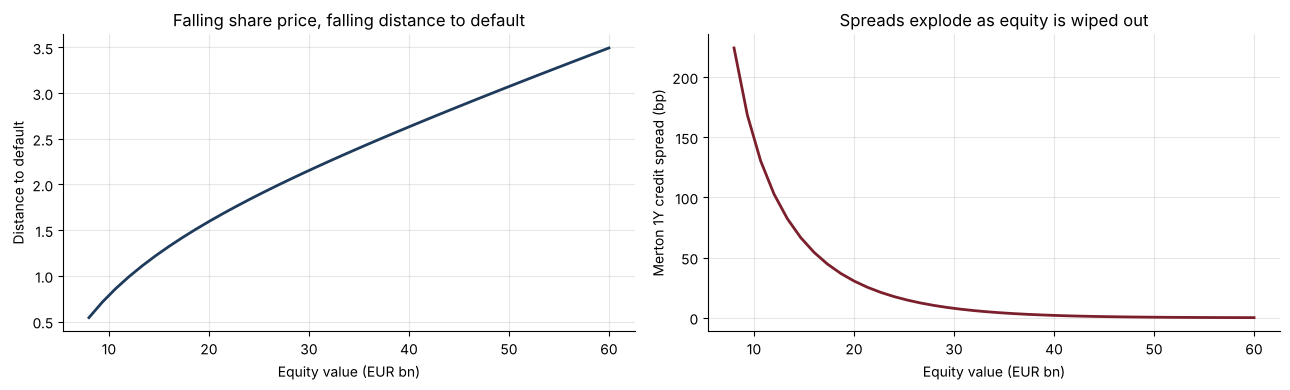

In [6]:
equity_levels = np.linspace(8, 60, 40)
res = [merton_solve(E=e, sigma_E=0.45 * (40 / e) ** 0.5, D=80.0, T=1.0, r=r) for e in equity_levels]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(equity_levels, [x["distance_to_default"] for x in res], color=NAVY, lw=2)
axes[0].set(xlabel="Equity value (EUR bn)", ylabel="Distance to default", title="Falling share price, falling distance to default")
axes[1].plot(equity_levels, [x["credit_spread"] * 1e4 for x in res], color=BORDEAUX, lw=2)
axes[1].set(xlabel="Equity value (EUR bn)", ylabel="Merton 1Y credit spread (bp)", title="Spreads explode as equity is wiped out")
plt.tight_layout(); plt.savefig("images/merton_equity_credit.png", dpi=150); plt.show()

Equity volatility is assumed to rise as the stock falls (a leverage effect), as observed in practice.

## 4. Merton vs the market: the credit spread puzzle

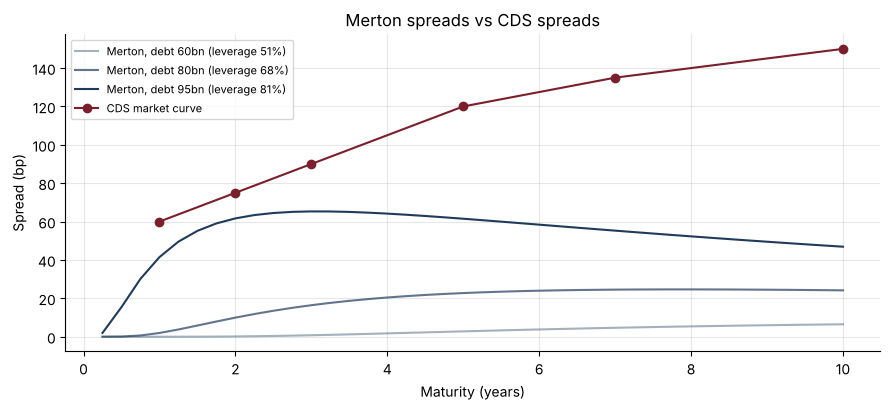

In [7]:
maturities = np.linspace(0.25, 10, 40)
plt.figure(figsize=(9, 4.2))
for D, a in [(60, 0.4), (80, 0.7), (95, 1.0)]:
    plt.plot(maturities, merton_spread_curve(firm["asset_value"], firm["asset_vol"], D, maturities, r) * 1e4,
             color=NAVY, alpha=a, label=f"Merton, debt {D}bn (leverage {D / firm['asset_value']:.0%})")
plt.plot(mats, spreads * 1e4, "o-", color=BORDEAUX, label="CDS market curve")
plt.xlabel("Maturity (years)"); plt.ylabel("Spread (bp)"); plt.legend(fontsize=8)
plt.title("Merton spreads vs CDS spreads")
plt.tight_layout(); plt.savefig("images/merton_vs_cds.png", dpi=150); plt.show()

**Reading the chart.** Merton produces almost no spread at short maturities: with
continuous asset paths, a firm far from its default point cannot default within a year.
The market still charges 60 bp. This gap is the **credit spread puzzle**; it is why practical
models add jumps, uncertainty about the default barrier (KMV, CreditGrades) or liquidity premia.

## Conclusions
- The bootstrapped hazard curve reprices every CDS exactly and gives market-implied
  default probabilities (about 10% over 5 years for this BBB name).
- A €10m 5Y protection costs an upfront of about €89k against the 100 bp coupon, with a
  CS01 of about €4,400 per bp.
- Merton links share price and credit risk, but underestimates short-dated spreads.
- **Next steps:** CDS index and tranches (project 12), wrong-way risk in CVA (project 15),
  KMV-style empirical mapping from distance to default to real-world PD.